# Análise Preditiva — Deliverable 1 (versão corrigida)
## Previsão de incidentes de segurança no uso de IA

**DAMA Intelligence** · Ana Luiza Proença, Gustavo Gomes, Kaique Lira e Ricardo Matteo · Ciência de Dados e Negócios, ESPM, 4º semestre, 2026

Esta é a versão do notebook do D1 corrigida a partir da pré-avaliação. O original (`DAMAAnalisePreditiva1.ipynb`) foi mantido para comparação. A pergunta continua a mesma: **um colaborador vai ter pelo menos um incidente de segurança no uso de IA?**

| Problema apontado ou encontrado | Correção | Tarefa no Jira |
|---|---|---|
| O notebook não rodava do início ao fim: a célula da curva ROC usava `modelo`, que nunca era criado | Pipeline completo, treinado e avaliado neste notebook | — |
| Faltava o diagnóstico da base | Seção 2: dimensões, nulos, cardinalidade, duplicatas e ausências disfarçadas, com tabela-resumo | SMAN-65, 154 a 159 |
| Acurácia enganosa com poucos positivos (2,8% no período todo; 1,5% com o corte temporal) | Baseline da classe majoritária e métricas ROC-AUC, PR-AUC e recall | SMAN-61, 147 a 150 |
| Desbalanceamento não tratado | `class_weight='balanced'`, sobreamostragem e subamostragem, aplicadas só no treino de cada dobra e comparadas com validação cruzada estratificada repetida | SMAN-62, 151 a 153 |
| Decisões do pré-processamento sem justificativa | Seção 5 explica cada uma | SMAN-66, 160 a 164 |
| A ordem da senioridade tinha "Diretor", que não existe na base, e "Gerente" virava categoria desconhecida | Ordem corrigida: Junior < Pleno < Senior < Especialista < Gerente | SMAN-163 |
| Cursos e tokens ausentes eram imputados pela mediana. Quem não tem registro não é dado faltante: tem zero cursos e zero tokens | Imputação por zero, com justificativa | SMAN-160 |
| O total de tokens somava só os de entrada | Entrada + saída | — |
| **Rigor temporal:** preditores e alvo eram somados sobre o mesmo período, ou seja, o incidente era "previsto" com informação gerada durante ou depois dele | Corte em 1º/jan/2026: preditores de jun a dez/2025, alvo de jan a jul/2026, com checagem variável a variável (seção 3) | — |

## 1. Configuração

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, precision_recall_curve, recall_score,
                             precision_score, roc_auc_score, roc_curve, accuracy_score)
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
DADOS = Path('../machine-learning-ia/Data/csv')   # base sintética do projeto (no Colab: suba os CSVs e use Path('.'))
SEED = 42
AZUL, LARANJA, VERDE, CINZA = '#2a78d6', '#eb6834', '#1baf7a', '#8f8e89'
TINTA, TINTA2, GRADE, FUNDO = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
plt.rcParams.update({'figure.facecolor': FUNDO, 'axes.facecolor': FUNDO, 'axes.edgecolor': GRADE, 'axes.labelcolor': TINTA2,
                     'xtick.color': TINTA2, 'ytick.color': TINTA2, 'axes.grid': True, 'grid.color': GRADE,
                     'axes.spines.top': False, 'axes.spines.right': False, 'lines.linewidth': 2, 'legend.frameon': False,
                     'axes.titleweight': 'bold', 'axes.titlesize': 11})

## 2. Diagnóstico da base

In [2]:
employees = pd.read_csv(DADOS / 'employees.csv')
training_records = pd.read_csv(DADOS / 'training_records.csv')
ai_usage = pd.read_csv(DADOS / 'ai_usage_logs.csv', usecols=['usage_id', 'employee_id', 'timestamp', 'input_tokens', 'output_tokens', 'request_status'])
security = pd.read_csv(DADOS / 'security_events.csv')

def diagnostico(nome, df):
    texto = df.select_dtypes(include=['object', 'string'])
    disfarcados = int(sum(texto[c].astype('string').str.strip().str.upper().isin(['', 'N/A', 'NA', 'NULL', 'NONE', '-']).sum() for c in texto))
    num = df.select_dtypes('number')
    return dict(tabela=nome, linhas=len(df), colunas=df.shape[1],
                nulos=', '.join(f'{c}: {df[c].isna().sum()}' for c in df.columns if df[c].isna().any()) or '—',
                duplicatas=int(df.duplicated().sum()), ausencias_disfarcadas=disfarcados, negativos=int((num < 0).sum().sum()),
                cardinalidade=', '.join(f'{c}: {df[c].nunique()}' for c in texto.columns))

resumo = pd.DataFrame([diagnostico('employees', employees), diagnostico('training_records', training_records),
                       diagnostico('ai_usage_logs', ai_usage), diagnostico('security_events', security)])
resumo

,tabela,linhas,colunas,nulos,duplicatas,ausencias_disfarcadas,negativos,cardinalidade
0,employees,2356,8,cost_center: 45,0,0,0,"employee_id: 2356, company_id: 18, department_..."
1,training_records,1597,10,"completion_date: 678, score: 678",0,0,0,"training_id: 1597, employee_id: 1056, company_..."
2,ai_usage_logs,269515,6,—,0,0,0,"usage_id: 269515, timestamp: 267345, employee_..."
3,security_events,69,9,—,0,0,0,"event_id: 69, company_id: 18, employee_id: 67,..."


| Tabela | Achado | Tratamento |
|---|---|---|
| `employees` | `cost_center` nulo em 45 linhas (1,9%) | Não entra no modelo |
| `training_records` | `completion_date` e `score` nulos fora de "Concluido" | Esperado: só contam cursos concluídos |
| `ai_usage_logs` | Nenhum nulo nas colunas usadas | — |
| `security_events` | Nenhum nulo; 69 eventos em 67 colaboradores | Alvo = ter pelo menos um evento |
| Todas | Nenhuma linha duplicada, nenhum texto vazio ou "N/A", nenhum número negativo | — |
| `employees.department_id` | 161 categorias, quase todas com poucos colaboradores | One-hot com `min_frequency` para agrupar as raras |

## 3. Base analítica e alvo

**Corte temporal.** A previsão é feita em **1º de janeiro de 2026**.

- Os preditores usam só o que existia até 31/12/2025.
- O alvo é ter pelo menos um incidente de **janeiro a julho de 2026**.
- Entram os colaboradores ativos contratados antes do corte, porque só eles têm histórico para prever.

Checagem variável a variável:

| Variável | Existe antes de 01/01/2026? | Como fica |
|---|---|---|
| `cursos_concluidos` | Só os cursos com `completion_date` até 31/12/2025 | Cursos concluídos depois do corte são descartados |
| `total_tokens` | Só os eventos de uso com `timestamp` até 31/12/2025 | Uso de 2026 é descartado |
| `incidentes_antes` | Incidentes de jun a dez/2025 | Variável nova: histórico de incidentes da pessoa |
| `seniority`, `department_id`, `company_id` | O cadastro guarda só a situação atual, não o histórico | Supõe-se que não mudaram no período; é uma limitação da base |
| `teve_incidente` (alvo) | Não: é o que se quer prever | Só eventos de jan a jul/2026 |

Eventos de segurança: 69 | antes do corte: 36 | depois: 33
Colaboradores na base: 2039 | com incidente em jan–jul/2026: 31 (1.5%)
Quem teve incidente antes e teve de novo depois: 1


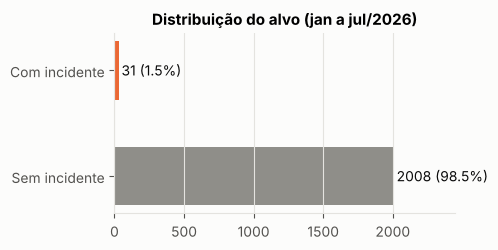

In [3]:
CORTE = pd.Timestamp('2026-01-01')
ai_usage['timestamp'] = pd.to_datetime(ai_usage.timestamp)
security['timestamp'] = pd.to_datetime(security.timestamp)
concl = training_records[(training_records.completion_status == 'Concluido') & (pd.to_datetime(training_records.completion_date) < CORTE)]
cursos = concl.groupby('employee_id').size().rename('cursos_concluidos')
uso_antes = ai_usage[ai_usage.timestamp < CORTE]
tokens = uso_antes.assign(t=uso_antes.input_tokens + uso_antes.output_tokens).groupby('employee_id').t.sum().rename('total_tokens')
incid_antes = security[security.timestamp < CORTE].groupby('employee_id').size().rename('incidentes_antes')
incid_depois = security[security.timestamp >= CORTE].groupby('employee_id').size().rename('incidentes')
base = employees[employees.active & (pd.to_datetime(employees.hire_date) < CORTE)]
df = base.join(cursos, on='employee_id').join(tokens, on='employee_id').join(incid_antes, on='employee_id').join(incid_depois, on='employee_id')
df['incidentes_antes'] = df.incidentes_antes.fillna(0)
df['incidentes'] = df.incidentes.fillna(0)
df['teve_incidente'] = (df.incidentes > 0).astype(int)
X = df[['seniority', 'department_id', 'company_id', 'cursos_concluidos', 'total_tokens', 'incidentes_antes']]
y = df.teve_incidente
print(f'Eventos de segurança: {len(security)} | antes do corte: {(security.timestamp < CORTE).sum()} | depois: {(security.timestamp >= CORTE).sum()}')
print(f'Colaboradores na base: {len(df)} | com incidente em jan–jul/2026: {y.sum()} ({y.mean():.1%})')
print(f'Quem teve incidente antes e teve de novo depois: {int(((df.incidentes_antes > 0) & (y == 1)).sum())}')

fig, ax = plt.subplots(figsize=(5, 2.6))
ax.barh(['Sem incidente', 'Com incidente'], [len(y) - y.sum(), y.sum()], color=[CINZA, LARANJA], height=0.55)
for i, v in enumerate([len(y) - y.sum(), y.sum()]):
    ax.text(v + 20, i, f'{v} ({v / len(y):.1%})', va='center', color=TINTA)
ax.set(title='Distribuição do alvo (jan a jul/2026)', xlim=(0, len(y) * 1.2)); ax.grid(axis='y', visible=False)
fig.tight_layout(); plt.show()

Os positivos são ainda mais raros que na versão sem corte: só os incidentes de 2026 contam. A divisão treino/teste e a validação cruzada são **estratificadas**, para que todas as partes tenham a mesma proporção de positivos.

## 4. Baseline trivial e escolha da métrica

In [4]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=SEED, stratify=y)
trivial = DummyClassifier(strategy='most_frequent').fit(X_tr, y_tr)
p0 = trivial.predict(X_te)
print(f'Classe majoritária — acurácia {accuracy_score(y_te, p0):.3f} | recall {recall_score(y_te, p0):.3f} | positivos no teste: {y_te.sum()}')

Classe majoritária — acurácia 0.985 | recall 0.000 | positivos no teste: 9


Prever "nunca há incidente" acerta 98,5% e não encontra nenhum caso. **A acurácia não serve aqui.**

**Métricas adotadas:**
- **PR-AUC (principal):** mede a qualidade do ranking na classe rara. O valor de referência de um sorteio é a própria taxa de positivos, cerca de 0,015.
- **ROC-AUC:** de apoio; 0,5 é o sorteio.
- **Recall e precisão:** calculados num limiar de decisão escolhido.

**Custo dos erros.**
- **Falso negativo:** um colaborador com risco que passa sem acompanhamento. Pode virar vazamento de dado sensível num prompt, com custo jurídico e de reputação alto.
- **Falso positivo:** um colaborador encaminhado a treinamento ou monitoramento sem necessidade. Custa algumas horas.

Como o falso negativo custa muito mais, o limiar prioriza **recall**: a meta é encontrar pelo menos 60% dos incidentes, desde que a precisão fique acima do sorteio.

## 5. Pré-processamento (decisões documentadas)

| Coluna | Tratamento | Justificativa |
|---|---|---|
| `cursos_concluidos`, `total_tokens`, `incidentes_antes` | Nulo vira **0** e depois padronização | Nulo aqui quer dizer "nenhum curso concluído" e "nenhum uso de IA". Imputar pela mediana inventaria cursos e uso que não existiram. A padronização deixa os coeficientes da regressão logística na mesma escala |
| `department_id`, `company_id` | One-hot com `handle_unknown='ignore'` e `min_frequency=5` | São categorias sem ordem. Um departamento novo no teste vira um vetor de zeros, sem erro, e os departamentos com menos de 5 colaboradores são agrupados |
| `seniority` | Ordinal com ordem explícita: Junior < Pleno < Senior < Especialista < Gerente | A senioridade tem ordem natural. A versão original usava "Diretor", que não existe na base |

Tudo fica dentro de um `Pipeline`. Médias, desvios e categorias são aprendidos **só no treino** de cada dobra e depois aplicados ao teste, sem vazamento.

In [5]:
def preprocessador():
    return ColumnTransformer([
        ('num', Pipeline([('zero', SimpleImputer(strategy='constant', fill_value=0)), ('escala', StandardScaler())]), ['cursos_concluidos', 'total_tokens', 'incidentes_antes']),
        ('nom', OneHotEncoder(handle_unknown='ignore', min_frequency=5), ['department_id', 'company_id']),
        ('ord', OrdinalEncoder(categories=[['Junior', 'Pleno', 'Senior', 'Especialista', 'Gerente']]), ['seniority'])])

class Reamostrado(ClassifierMixin, BaseEstimator):
    """Reamostra só o conjunto de treino recebido em fit (nunca a validação). modo: 'sobre' ou 'sub'."""
    def __init__(self, estimador, modo='sobre', random_state=SEED):
        self.estimador, self.modo, self.random_state = estimador, modo, random_state
    def fit(self, X, y):
        rng = np.random.default_rng(self.random_state)
        y = np.asarray(y); pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
        if self.modo == 'sobre':
            idx = np.r_[neg, rng.choice(pos, size=len(neg), replace=True)]
        else:
            idx = np.r_[pos, rng.choice(neg, size=len(pos) * 3, replace=False)]   # 1 positivo para 3 negativos
        self.est_ = clone(self.estimador).fit(X[idx], y[idx])
        self.classes_ = self.est_.classes_
        return self
    def predict_proba(self, X):
        return self.est_.predict_proba(X)
    def predict(self, X):
        return self.est_.predict(X)

## 6. Tratamento do desbalanceamento: comparação com validação cruzada estratificada repetida

São 5 dobras estratificadas repetidas 5 vezes, num total de 25 ajustes por configuração. Com só 67 positivos, uma única divisão daria um resultado muito dependente da sorte. A repetição mostra a média **e** a variação.

In [6]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
logistica = LogisticRegression(max_iter=3000, C=0.3)
floresta = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=SEED, n_jobs=-1)
configs = {
    'Logística · sem tratamento': logistica,
    'Logística · class_weight=balanced': LogisticRegression(max_iter=3000, C=0.3, class_weight='balanced'),
    'Logística · sobreamostragem no treino': Reamostrado(logistica, 'sobre'),
    'Logística · subamostragem no treino': Reamostrado(logistica, 'sub'),
    'Random Forest · sem tratamento': floresta,
    'Random Forest · class_weight=balanced': RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight='balanced', random_state=SEED, n_jobs=-1),
    'Random Forest · sobreamostragem no treino': Reamostrado(floresta, 'sobre'),
    'Random Forest · subamostragem no treino': Reamostrado(floresta, 'sub'),
}
linhas = []
for nome, est in configs.items():
    r = cross_validate(Pipeline([('pre', preprocessador()), ('clf', est)]), X, y, cv=cv, scoring=['average_precision', 'roc_auc'], n_jobs=1, error_score='raise')
    linhas.append(dict(configuracao=nome, pr_auc=r['test_average_precision'].mean(), pr_auc_dp=r['test_average_precision'].std(),
                       roc_auc=r['test_roc_auc'].mean(), roc_auc_dp=r['test_roc_auc'].std()))
cv_res = pd.DataFrame(linhas).set_index('configuracao').sort_values('pr_auc', ascending=False)
cv_res.round(3)

,pr_auc,pr_auc_dp,roc_auc,roc_auc_dp
configuracao,,,,
Random Forest · sem tratamento,0.082,0.059,0.701,0.064
Random Forest · class_weight=balanced,0.063,0.049,0.679,0.069
Random Forest · subamostragem no treino,0.048,0.030,0.650,0.082
Logística · sem tratamento,0.047,0.033,0.652,0.106
Random Forest · sobreamostragem no treino,0.047,0.015,0.689,0.069
Logística · class_weight=balanced,0.045,0.024,0.586,0.101
Logística · sobreamostragem no treino,0.043,0.023,0.573,0.104
Logística · subamostragem no treino,0.035,0.014,0.620,0.101


## 7. De onde vem o sinal

O modelo usa quatro grupos de informação: empresa, departamento, senioridade e comportamento individual (cursos e tokens). A **ablação** treina a mesma configuração com cada grupo isolado, para ver qual deles carrega o sinal.

In [7]:
melhor = cv_res.index[0]
est_melhor = configs[melhor]
def pipe_com(colunas):
    num = [c for c in ['cursos_concluidos', 'total_tokens', 'incidentes_antes'] if c in colunas]
    nom = [c for c in ['department_id', 'company_id'] if c in colunas]
    partes = []
    if num: partes.append(('num', Pipeline([('zero', SimpleImputer(strategy='constant', fill_value=0)), ('escala', StandardScaler())]), num))
    if nom: partes.append(('nom', OneHotEncoder(handle_unknown='ignore', min_frequency=5), nom))
    if 'seniority' in colunas: partes.append(('ord', OrdinalEncoder(categories=[['Junior', 'Pleno', 'Senior', 'Especialista', 'Gerente']]), ['seniority']))
    return Pipeline([('pre', ColumnTransformer(partes)), ('clf', clone(est_melhor))])

ablacao = []
for nome, cols in {'Todas as variáveis': list(X.columns), 'Só empresa': ['company_id'], 'Só departamento': ['department_id'],
                   'Só cursos e tokens (comportamento individual)': ['cursos_concluidos', 'total_tokens'], 'Só incidentes anteriores': ['incidentes_antes'], 'Só senioridade': ['seniority']}.items():
    r = cross_validate(pipe_com(cols), X, y, cv=cv, scoring=['average_precision', 'roc_auc'])
    ablacao.append(dict(variaveis=nome, pr_auc=r['test_average_precision'].mean(), roc_auc=r['test_roc_auc'].mean(), roc_auc_dp=r['test_roc_auc'].std()))
ablacao = pd.DataFrame(ablacao).set_index('variaveis')
taxa_empresa = df.groupby('company_id').agg(colaboradores=('teve_incidente', 'size'), incidentes=('teve_incidente', 'sum'), taxa=('teve_incidente', 'mean'))
print('Correlação entre tamanho da empresa (colaboradores na base) e taxa de incidentes por colaborador:',
      round(taxa_empresa[['colaboradores', 'taxa']].corr(method='spearman').iloc[0, 1], 3))
ablacao.round(3)

Correlação entre tamanho da empresa (colaboradores na base) e taxa de incidentes por colaborador: -0.744


,pr_auc,roc_auc,roc_auc_dp
variaveis,,,
Todas as variáveis,0.082,0.701,0.064
Só empresa,0.044,0.593,0.128
Só departamento,0.070,0.704,0.086
Só cursos e tokens (comportamento individual),0.026,0.542,0.070
Só incidentes anteriores,0.015,0.480,0.025
Só senioridade,0.017,0.475,0.094


## 8. Avaliação no conjunto de teste (30%, estratificado)

Random Forest · sem tratamento — ROC-AUC 0.644 | PR-AUC 0.025 (sorteio: 0.015)
Limiar 0.012: recall 0.67 | precisão 0.029 | colaboradores sinalizados 204 de 612


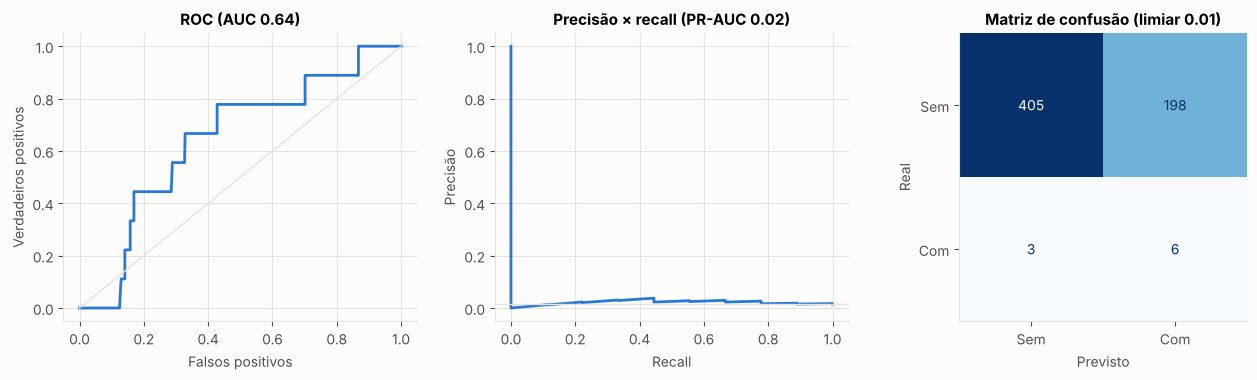

In [8]:
modelo = Pipeline([('pre', preprocessador()), ('clf', clone(est_melhor))]).fit(X_tr, y_tr)
p = modelo.predict_proba(X_te)[:, 1]
prec, rec, lim = precision_recall_curve(y_te, p)
ok = np.where(rec[:-1] >= 0.6)[0]
limiar = float(lim[ok[-1]]) if len(ok) else 0.5      # o maior limiar que ainda encontra 60% dos incidentes
pred = (p >= limiar).astype(int)
print(f'{melhor} — ROC-AUC {roc_auc_score(y_te, p):.3f} | PR-AUC {average_precision_score(y_te, p):.3f} (sorteio: {y_te.mean():.3f})')
print(f'Limiar {limiar:.3f}: recall {recall_score(y_te, pred):.2f} | precisão {precision_score(y_te, pred):.3f} | colaboradores sinalizados {pred.sum()} de {len(pred)}')

fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(13, 3.9))
fpr, tpr, _ = roc_curve(y_te, p)
a1.plot(fpr, tpr, color=AZUL); a1.plot([0, 1], [0, 1], color=GRADE, lw=1)
a1.set(title=f'ROC (AUC {roc_auc_score(y_te, p):.2f})', xlabel='Falsos positivos', ylabel='Verdadeiros positivos')
a2.plot(rec, prec, color=AZUL); a2.axhline(y_te.mean(), color=GRADE, lw=1)
a2.set(title=f'Precisão × recall (PR-AUC {average_precision_score(y_te, p):.2f})', xlabel='Recall', ylabel='Precisão')
ConfusionMatrixDisplay.from_predictions(y_te, pred, display_labels=['Sem', 'Com'], cmap='Blues', colorbar=False, ax=a3)
a3.set(title=f'Matriz de confusão (limiar {limiar:.2f})', xlabel='Previsto', ylabel='Real'); a3.grid(False)
fig.tight_layout(); plt.show()

In [9]:
imp = permutation_importance(modelo, X_te, y_te, scoring='average_precision', n_repeats=20, random_state=SEED)
pd.DataFrame({'variavel': X.columns, 'queda_pr_auc': imp.importances_mean, 'desvio': imp.importances_std}).sort_values('queda_pr_auc', ascending=False).round(4)

,variavel,queda_pr_auc,desvio
2,company_id,0.0018,0.0083
4,total_tokens,0.0002,0.0013
5,incidentes_antes,-0.0013,0.0000
3,cursos_concluidos,-0.0014,0.0009
0,seniority,-0.0019,0.0020
1,department_id,-0.0038,0.0052


## 9. Conclusões da versão corrigida

In [10]:
print(f"Melhor configuração na validação cruzada: {melhor} — PR-AUC {cv_res.loc[melhor, 'pr_auc']:.3f} ± {cv_res.loc[melhor, 'pr_auc_dp']:.3f}, "
      f"ROC-AUC {cv_res.loc[melhor, 'roc_auc']:.3f} ± {cv_res.loc[melhor, 'roc_auc_dp']:.3f} (sorteio: PR-AUC {y.mean():.3f}, ROC-AUC 0,5)")
print(f"Ablação (ROC-AUC): só empresa {ablacao.loc['Só empresa', 'roc_auc']:.3f} | só cursos e tokens {ablacao.loc['Só cursos e tokens (comportamento individual)', 'roc_auc']:.3f} "
      f"| todas {ablacao.loc['Todas as variáveis', 'roc_auc']:.3f}")

Melhor configuração na validação cruzada: Random Forest · sem tratamento — PR-AUC 0.082 ± 0.059, ROC-AUC 0.701 ± 0.064 (sorteio: PR-AUC 0.015, ROC-AUC 0,5)
Ablação (ROC-AUC): só empresa 0.593 | só cursos e tokens 0.542 | todas 0.701


**Leitura dos resultados (com o corte temporal)**

- **Base menor e mais rara.** Com o corte, sobram 2.039 colaboradores e só 31 incidentes em jan a jul/2026 (1,5%). O sorteio tem PR-AUC de 0,015.
- **Tratamento do desbalanceamento.** Nenhuma técnica melhora o ranking. A melhor configuração é a Random Forest sem tratamento, com PR-AUC de 0,082 ± 0,059 e ROC-AUC de 0,701 ± 0,064. O reequilíbrio muda a escala das probabilidades, não a ordem dos colaboradores. Por isso, o desbalanceamento é tratado na **escolha do limiar**, que prioriza recall.
- **O sinal é da unidade, não da pessoa.**
    - Só com o departamento, o ROC-AUC é 0,704, igual ao modelo completo. Só com a empresa, é 0,593.
    - Só com cursos e tokens, fica em 0,542. Só com incidentes anteriores, em 0,480; apenas 1 pessoa teve incidente antes e depois do corte. Os dois ficam no nível de um sorteio.
    - Unidades menores têm mais incidentes por colaborador (Spearman de −0,74 entre o tamanho da empresa e a taxa), porque o número de eventos por empresa varia pouco.
- **No teste, o sinal some.** O ROC-AUC é 0,644 e a PR-AUC, 0,025. Na permutação, nenhuma variável tem queda de PR-AUC acima do próprio desvio. Para achar 6 dos 9 incidentes do teste, seria preciso sinalizar 204 de 612 colaboradores (33%), com precisão de 2,9%.
- **Comparação com a versão sem corte.** O ROC-AUC na validação cruzada quase não mudou (0,715 para 0,701). O vazamento temporal não inflava o resultado, porque os incidentes não se repetem. Ainda assim, o corte é obrigatório para a avaliação ser válida.
- **Coerência com a Estatística Multivariada:** lá, a capacitação também não reduz incidentes (H2 não confirmada; razão de chances de 0,82, IC 95% de 0,54 a 1,25).

O modelo não sustenta decisão sobre pessoas. Por isso, no Deliverable 2, a Análise Preditiva passa a prever **demanda e custo de IA**, uma pergunta que a base sustenta (`Deliverable2/08_Analise_Preditiva`).